In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [4]:
df.shape

(1338, 7)

In [5]:
df.size

9366

### Cheking Unique Values Of Simple Columns

In [6]:
for col in df.columns:
    if df[col].nunique() <= 10:
        print(f"\nColumn:{col}")
        print(df[col].unique())


Column:sex
['female' 'male']

Column:children
[0 1 3 2 5 4]

Column:smoker
['yes' 'no']

Column:region
['southwest' 'southeast' 'northwest' 'northeast']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### Checking Missing Values

In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### Checking Duplicate Values

In [10]:
print(df.duplicated().sum())

1


### Feature Selection

In [15]:
df.drop(columns=["region"], inplace=True)
df.head()

,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


### Outlier Detection

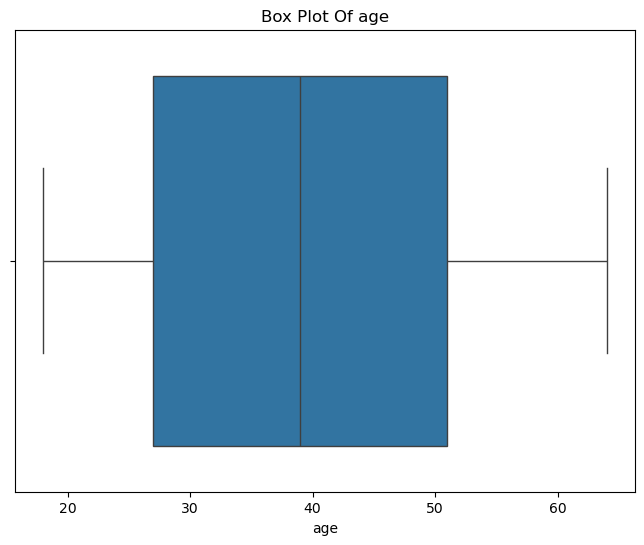

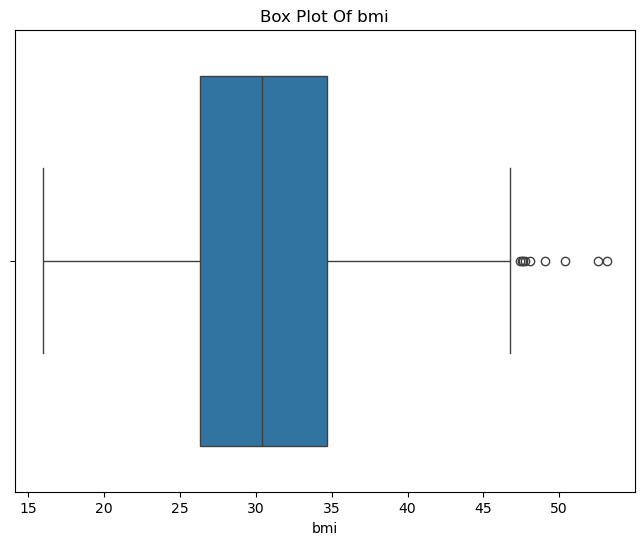

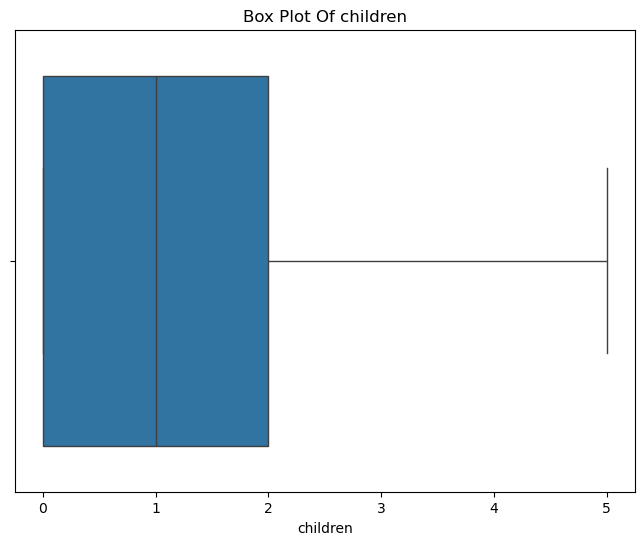

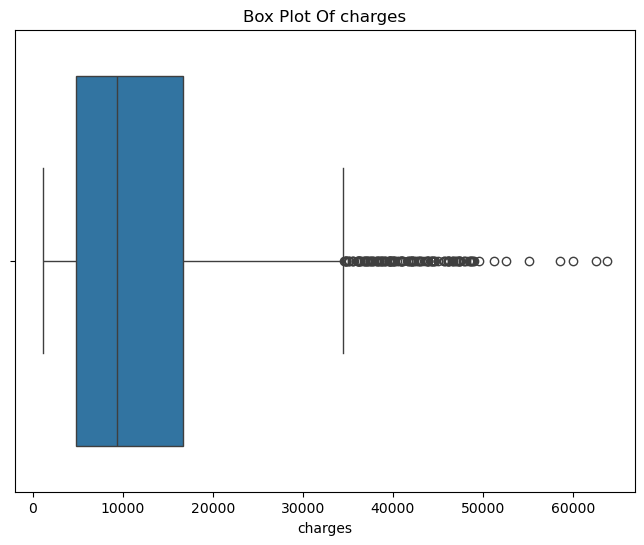

In [11]:
numerical_columns=df.select_dtypes(include="number").columns
for col in numerical_columns:
    plt.figure(figsize=(8,6))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot Of {col}")
    plt.show()

### Outlier Handling

In [13]:
outlier_cols=["bmi","charges"]
for col in outlier_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
   
    IQR=Q3-Q1
    
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    
    df[col]=np.clip(
    df[col],
    lower_bound,
    upper_bound
   )

print("Outlier Clipping Completed.")

Outlier Clipping Completed.


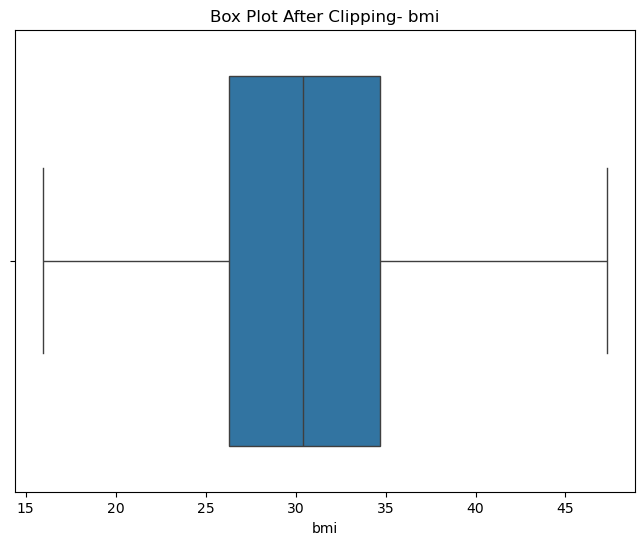

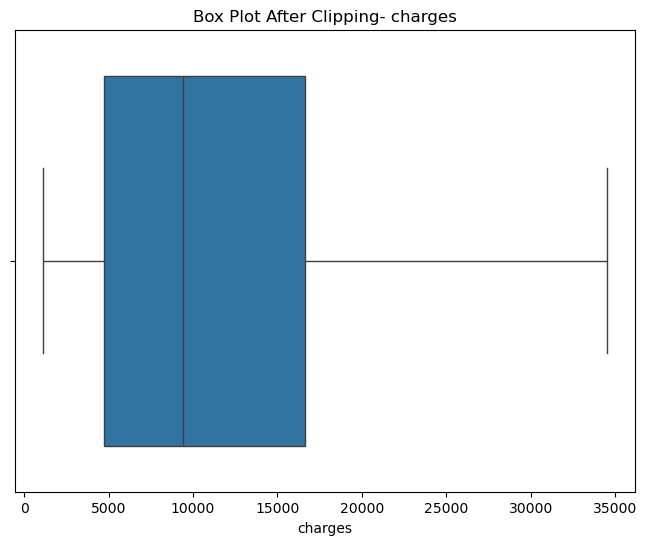

In [14]:
for col in outlier_cols:
    plt.figure(figsize=(8,6))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot After Clipping- {col}")
    plt.show()